# Loading the Dataset

In [1]:
from google.colab import auth
from google.colab import userdata
import requests
import json
import subprocess
auth.authenticate_user()
email = subprocess.getoutput("gcloud config get-value account")
print(f"Current Google User: {email}")

Current Google User: kopach.pn@ucu.edu.ua


In [2]:
DRIVE_ROOT = '/content/drive/MyDrive/datasets/hw2_train-s3_val-s3/' if email.startswith('kopach') else \
              '/content/drive/MyDrive/ai-hw2/hw2_train-s3_val-s3'

In [ ]:
!pip install -q ultralytics pycocotools
!pip install pathlib

In [3]:
import shutil
from pathlib import Path
from google.colab import drive
import torch
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import CocoDetection, wrap_dataset_for_transforms_v2
from torchvision.transforms import v2 as T
from PIL import Image
import pandas as pd
import yaml
import numpy as np
import math, time, json, random
from collections import Counter

In [4]:
drive.mount('/content/drive', force_remount=True)
ROOT = Path(DRIVE_ROOT)

if not ROOT.exists():
    print('Copying dataset to local disk...')
    shutil.copytree(DRIVE_ROOT, ROOT)

Mounted at /content/drive


# Two-stage Anchor-based

In [5]:
from collections import defaultdict
import matplotlib.pyplot as plt, matplotlib.patches as patches
from torchvision.ops import box_iou
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.anchor_utils import AnchorGenerator
import torchvision.transforms.functional as TF
from tqdm.auto import tqdm
from pycocotools.cocoeval import COCOeval
from pycocotools.coco import COCO
import re


DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU - turn on the GPU runtime')

Device: Tesla T4


In [6]:
OUT = Path('/content/drive/MyDrive/hw2_runs/frcnn')
OUT.mkdir(parents=True, exist_ok=True)


EPOCHS = 6              # final model
EXP_EPOCHS = 2          # each parameter experiment
EXP_TRAIN_IMAGES = 2000 # experiments use a part of the data, so they finish in reasonable time
EXP_VAL_IMAGES = 500

BATCH_SIZE = 2          # lower MIN_SIZE to 800 if you get CUDA out of memory
LR = 0.005
MIN_SIZE, MAX_SIZE = 1024, 1824
MAX_DET = 300           # scenes are dense
SCORE_THRESH = 0.01     # low threshold is standard for mAP

In [7]:
names = yaml.safe_load(open(ROOT / 'train' / 'data.yaml'))['names']
names = [names[k] for k in sorted(names)] if isinstance(names, dict) else names
NUM_CLASSES = len(names)


class CocoFrames(Dataset):
    def __init__(self, split, limit=None, augment=False):
        self.coco = COCO(str(ROOT / split / 'annotations_coco.json'))
        self.augment = augment

        # Remove annotations with an unlisted category or zero size, for training and evaluation alike
        anns = self.coco.dataset['annotations']
        good = [a for a in anns if a['category_id'] in self.coco.cats and a['bbox'][2] > 0 and a['bbox'][3] > 0]
        for a in good:
            a.setdefault('iscrowd', 0)
            a.setdefault('area', a['bbox'][2] * a['bbox'][3])
        self.coco.dataset['annotations'] = good
        self.coco.createIndex()

        # Images are in <split>/ or <split>/images/. Keep only frames that exist on disk.
        for self.folder in [ROOT / split, ROOT / split / 'images']:
            self.ids = [i for i, im in sorted(self.coco.imgs.items()) if (self.folder / im['file_name']).exists()]
            if self.ids:
                break
        assert self.ids, f'No images from the {split} json were found on disk'
        total = len(self.ids)
        if limit and limit < total:  # evenly spaced, so every clip stays represented
            self.ids = [self.ids[k] for k in np.linspace(0, total - 1, limit).astype(int)]

        # COCO category id -> 0-based class index from data.yaml
        cats = sorted(self.coco.cats.values(), key=lambda c: c['id'])
        if all(c['name'] in names for c in cats):
            self.cat2cls = {c['id']: names.index(c['name']) for c in cats}
        else:
            print('WARNING: json category names differ from data.yaml, matching them by order')
            self.cat2cls = {c['id']: k for k, c in enumerate(cats)}
        print(f'{split}: using {len(self.ids):,} frames ({len(self.coco.imgs):,} in json, {total:,} on disk), '
              f'dropped {len(anns) - len(good):,} bad annotations')

    def __len__(self):
        return len(self.ids)

    def boxes_and_labels(self, image_id):
        boxes, labels = [], []
        for a in self.coco.imgToAnns[image_id]:
            x, y, w, h = a['bbox']
            if not a['iscrowd']:
                boxes.append([x, y, x + w, y + h])
                labels.append(self.cat2cls[a['category_id']] + 1)
        return torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4), torch.tensor(labels, dtype=torch.int64)

    def __getitem__(self, idx):
        image_id = self.ids[idx]
        image = TF.to_tensor(Image.open(self.folder / self.coco.imgs[image_id]['file_name']).convert('RGB'))
        boxes, labels = self.boxes_and_labels(image_id)
        if self.augment and torch.rand(1) < 0.5:  # horizontal flip
            image = image.flip(-1)
            boxes[:, [0, 2]] = image.shape[-1] - boxes[:, [2, 0]]
        return image, {'boxes': boxes, 'labels': labels, 'image_id': image_id}


class TestFrames(Dataset):
    def __init__(self):
        self.paths = sorted((ROOT / 'test' / 'images').rglob('*.jpg'))

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        p = self.paths[idx]  # .../clip_001/0000001.jpg -> clip_001_0000001
        return TF.to_tensor(Image.open(p).convert('RGB')), {'image_id': f'{p.parent.name}_{p.stem}'}


def collate(batch):
    return tuple(zip(*batch))


train_ds = CocoFrames('train', augment=True)
val_ds = CocoFrames('val')
print(NUM_CLASSES, 'classes:', names)

loading annotations into memory...
Done (t=6.62s)
creating index...
index created!
creating index...
index created!
train: using 8,090 frames (24,201 in json, 8,090 on disk), dropped 0 bad annotations
loading annotations into memory...
Done (t=1.27s)
creating index...
index created!
creating index...
index created!
val: using 951 frames (2,846 in json, 951 on disk), dropped 0 bad annotations
8 classes: ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']


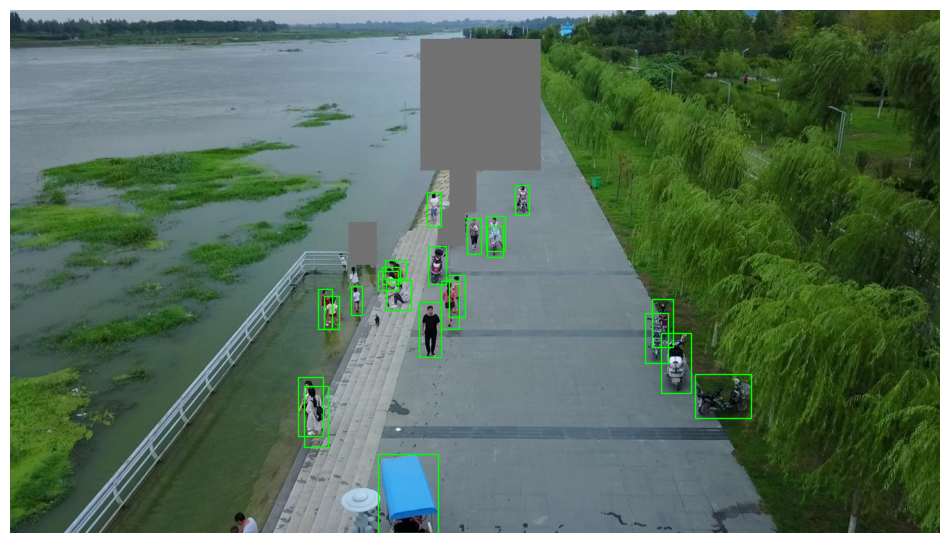

In [ ]:
image, target = train_ds[0]
fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(image.permute(1, 2, 0))
for x1, y1, x2, y2 in target['boxes'].tolist():
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color='lime', linewidth=1))
ax.axis('off')
plt.show()

## Training setup

In [8]:
def build_model(**params):
    model = fasterrcnn_resnet50_fpn_v2(
        weights=FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT,
        min_size=MIN_SIZE, max_size=MAX_SIZE,
        box_detections_per_img=MAX_DET, box_score_thresh=SCORE_THRESH,
        **params,
    )
    # Smaller anchors. Still 3 per location, so the pretrained RPN weights fit.
    model.rpn.anchor_generator = AnchorGenerator(((16,), (32,), (64,), (128,), (256,)), ((0.5, 1.0, 2.0),) * 5)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES + 1)  # +1 for background
    return model.to(DEVICE)


def train_model(name, epochs, dataset, **params):
    """Trains and saves after every epoch. An existing checkpoint is continued, or used as is if finished.
    Delete the file in OUT to retrain the same name from scratch."""
    torch.manual_seed(0)
    model = build_model(**params)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, collate_fn=collate, drop_last=True)
    optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad],
                                lr=LR, momentum=0.9, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, total_steps=epochs * len(loader),
                                                    pct_start=0.1, cycle_momentum=False)
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE == 'cuda')

    path = OUT / f'{name}_{epochs}ep.pt'
    start = 0
    if path.exists():
        state = torch.load(path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(state['model'])
        start = state['epoch']
        if start < epochs:
            optimizer.load_state_dict(state['optimizer'])
            scheduler.load_state_dict(state['scheduler'])
            scaler.load_state_dict(state['scaler'])
        print(f'{name}: loaded checkpoint, {start}/{epochs} epochs done')

    for epoch in range(start, epochs):
        model.train()
        total = 0.0
        for images, targets in tqdm(loader, desc=f'{name} epoch {epoch + 1}/{epochs}'):
            images = [im.to(DEVICE) for im in images]
            targets = [{k: t[k].to(DEVICE) for k in ('boxes', 'labels')} for t in targets]
            with torch.autocast('cuda', enabled=DEVICE == 'cuda'):
                loss = sum(model(images, targets).values())
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            total += loss.item()
        print(f'{name} epoch {epoch + 1}: mean loss {total / len(loader):.4f}')

        state = {'model': model.state_dict(), 'epoch': epoch + 1}
        if epoch + 1 < epochs:  # finished runs don't need the larger resume state
            state.update(optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(), scaler=scaler.state_dict())
        temp = path.with_suffix('.tmp')
        torch.save(state, temp)
        temp.replace(path)  # a disconnect during saving can't corrupt the checkpoint
    return model

In [9]:
@torch.no_grad()
def predict(model, dataset):
    model.eval()
    loader = DataLoader(dataset, batch_size=4, num_workers=2, collate_fn=collate)
    results = {}
    for images, targets in tqdm(loader, desc='predict'):
        with torch.autocast('cuda', enabled=DEVICE == 'cuda'):
            outputs = model([im.to(DEVICE) for im in images])
        for out, t in zip(outputs, targets):
            results[t['image_id']] = ((out['labels'] - 1).cpu().numpy(),
                                      out['scores'].float().cpu().numpy(),
                                      out['boxes'].float().cpu().numpy())
    return results


def coco_eval(results, dataset):
    cls2cat = {k: cat for cat, k in dataset.cat2cls.items()}
    detections = [
        {'image_id': image_id, 'category_id': cls2cat[int(c)], 'score': float(s),
         'bbox': [float(x1), float(y1), float(x2 - x1), float(y2 - y1)]}
        for image_id, (cls, scores, boxes) in results.items()
        for c, s, (x1, y1, x2, y2) in zip(cls, scores, boxes)
    ]
    assert detections, 'The model produced no detections'
    ev = COCOeval(dataset.coco, dataset.coco.loadRes(detections), 'bbox')
    ev.params.imgIds = dataset.ids  # only the frames in the subset
    ev.params.maxDets = [1, 10, MAX_DET]
    ev.evaluate()
    ev.accumulate()

    precision = ev.eval['precision']  # [IoU threshold, recall, class, area range, max detections]
    def mean_ap(p):
        return float(p[p > -1].mean()) if (p > -1).any() else float('nan')
    metrics = {'mAP': mean_ap(precision[:, :, :, 0, -1]),
               'AP50': mean_ap(precision[0, :, :, 0, -1]),
               'AP_small': mean_ap(precision[:, :, :, 1, -1])}
    per_class = {names[dataset.cat2cls[cat]]: mean_ap(precision[:, :, k, 0, -1]) for k, cat in enumerate(ev.params.catIds)}
    return metrics, per_class


@torch.no_grad()
def inference_ms(model, dataset, n=100):
    """Milliseconds per image for the model itself, one image at a time, without file loading."""
    model.eval()
    images = [dataset[i][0].to(DEVICE) for i in range(min(n, len(dataset)))]
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for image in images:
        model([image])
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    return 1000 * (time.perf_counter() - start) / len(images)

In [ ]:
EXPERIMENTS = {
    'baseline':   {},  # torchvision defaults: 2000 train / 1000 test proposals, 25% positive RoIs
    'rpn_low':    {'rpn_post_nms_top_n_train': 500,  'rpn_post_nms_top_n_test': 250},
    'rpn_high':   {'rpn_post_nms_top_n_train': 4000, 'rpn_post_nms_top_n_test': 2000},
    'roi_pos_50': {'box_positive_fraction': 0.5},
}

exp_train = CocoFrames('train', limit=EXP_TRAIN_IMAGES, augment=True)
exp_val = CocoFrames('val', limit=EXP_VAL_IMAGES)

rows = []
for name, params in EXPERIMENTS.items():
    model = train_model(name, EXP_EPOCHS, exp_train, **params)
    metrics, _ = coco_eval(predict(model, exp_val), exp_val)
    rows.append({'run': name, **metrics, 'ms_per_image': inference_ms(model, exp_val)})
    del model
    torch.cuda.empty_cache()

experiments = pd.DataFrame(rows).set_index('run').round(4)
experiments.to_csv(OUT / 'experiments.csv')
best_run = experiments['mAP'].idxmax()
print('Best run:', best_run)
experiments

loading annotations into memory...
Done (t=7.21s)
creating index...
index created!
creating index...
index created!
train: using 2,000 frames (24,201 in json, 8,090 on disk), dropped 0 bad annotations
loading annotations into memory...
Done (t=0.79s)
creating index...
index created!
creating index...
index created!
val: using 500 frames (2,846 in json, 951 on disk), dropped 0 bad annotations


baseline epoch 1/2:   0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_441/2223972292.py:53: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


baseline epoch 1: mean loss 1.0103


baseline epoch 2/2:   0%|          | 0/1000 [00:00<?, ?it/s]

baseline epoch 2: mean loss 0.7787


... (17 outputs left out)

roi_pos_50 epoch 2: mean loss 1.1738


predict:   0%|          | 0/125 [00:00<?, ?it/s]

Loading and preparing results...
DONE (t=0.12s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=32.55s).
Accumulating evaluation results...
DONE (t=1.85s).
Best run: roi_pos_50


,mAP,AP50,AP_small,ms_per_image
run,,,,
baseline,0.2419,0.4974,0.1135,383.4393
rpn_low,0.2347,0.4723,0.1161,352.7829
rpn_high,0.2338,0.4857,0.1146,431.7994
roi_pos_50,0.2446,0.5005,0.1282,435.4844


In [ ]:
model = train_model('final', EPOCHS, train_ds, **EXPERIMENTS[best_run])

val_results = predict(model, val_ds)
metrics, per_class = coco_eval(val_results, val_ds)
ms = inference_ms(model, val_ds)

report = pd.Series({**metrics, 'ms_per_image': ms, 'FPS': 1000 / ms}).round(4)
report.to_csv(OUT / 'final_metrics.csv')
print('Parameters from the study:', EXPERIMENTS[best_run] or 'defaults')
print(report, '\n')
print(pd.Series(per_class, name='AP per class').sort_values().round(4))

final epoch 1/6:   0%|          | 0/4045 [00:00<?, ?it/s]

/tmp/ipykernel_441/2223972292.py:53: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


final epoch 1: mean loss 1.3465


final epoch 2/6:   0%|          | 0/4045 [00:00<?, ?it/s]

KeyboardInterrupt: 

# Submission

In [10]:
model = (m := build_model(), m.load_state_dict(torch.load(OUT / 'final_6ep.pt', map_location=DEVICE, weights_only=False)['model']))[0].eval()

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 180MB/s]


In [11]:
def make_submission(model):
    """Predicts every test image and returns {image_id: (cls, scores, boxes)}. Nothing is written to disk."""
    return predict(model, TestFrames())  # always every test image, never a subset


def save_submission(results, path):
    """Writes predictions as: image_id,PredictionString with "cls score x y w h" for each box.
    Every test image gets a row, and a frame with no boxes gets an empty PredictionString."""
    def to_text(cls, scores, boxes):
        return ' '.join(f'{c} {s:.4f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}'
                        for c, s, (x1, y1, x2, y2) in zip(cls, scores, boxes))

    submission = pd.DataFrame({'image_id': sorted(results)})
    submission['PredictionString'] = submission['image_id'].map(lambda image_id: to_text(*results[image_id]))
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    submission.to_csv(path, index=False)
    print(f'Saved {path} with {len(submission):,} rows')
    return submission


In [12]:
prediction = make_submission(model)
submission = save_submission(prediction, OUT / 'submission_faster_rcnn.csv')
submission.head()

predict:   0%|          | 0/953 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/hw2_runs/frcnn/submission_faster_rcnn.csv with 3,811 rows


,image_id,PredictionString
0,clip_001_0000001,0 0.9883 1713.3 788.2 52.7 142.7 0 0.9860 1655...
1,clip_001_0000002,0 0.9865 1724.6 794.2 53.2 144.5 0 0.9851 695....
2,clip_001_0000003,0 0.9854 1665.8 796.5 65.4 153.5 0 0.9854 827....
3,clip_001_0000004,0 0.9841 1667.1 799.1 64.8 154.8 0 0.9825 1726...
4,clip_001_0000005,0 0.9860 793.4 718.7 43.1 108.8 0 0.9849 940.0...
